In [3]:
%%bash
git clone https://github.com/MosharofHossainDipo/yolov12_dataset

Cloning into 'yolov12_dataset'...
Updating files: 100% (14579/14579), done.


In [4]:
# 1. Kiểm tra xem máy ảo Colab đã gắn card NVIDIA Tesla T4 (16GB VRAM) chưa
!nvidia-smi

# 2. Cài đặt thư viện Ultralytics (hỗ trợ kiến trúc YOLOv12) và Roboflow
!pip install -q ultralytics>=8.3.0 roboflow pyyaml

import torch
import ultralytics

# Kiểm tra cấu hình hệ thống
ultralytics.checks()
assert torch.cuda.is_available(), "LỖI: Bạn chưa bật GPU! Vào Runtime -> Change runtime type -> chọn T4 GPU."
print(f"\n[OK] Đã nhận diện GPU: {torch.cuda.get_device_name(0)}")

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.9/112.6 GB disk)

[OK] Đã nhận diện GPU: Tesla T4


In [5]:
import shutil
from pathlib import Path
from roboflow import Roboflow

# Định nghĩa đường dẫn lưu dữ liệu thô trên ổ đĩa ảo của Google Colab
RAW_DATA_DIR = Path("/content/data/raw")

# Xóa thư mục cũ nếu chạy lại cell để tránh trùng lặp file
if RAW_DATA_DIR.exists():
    shutil.rmtree(RAW_DATA_DIR)
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

# =====================================================================
# LỰA CHỌN PHƯƠNG THỨC TẢI DATASET:
# - Đặt USE_ROBOFLOW_API = True nếu bạn muốn tải bằng API Key từ Roboflow
# - Đặt USE_ROBOFLOW_API = False để kéo trực tiếp dataset gốc từ bài báo Dipo et al. (2025)
# =====================================================================
USE_ROBOFLOW_API = False

if USE_ROBOFLOW_API:
    # Điền các thông số lấy từ cửa sổ "Export Dataset -> Show download code" trên Roboflow:
    ROBOFLOW_API_KEY = "DÁN_API_KEY_CỦA_BẠN_VÀO_ĐÂY"
    WORKSPACE_ID = "DÁN_WORKSPACE_VÀO_ĐÂY"
    PROJECT_ID = "DÁN_PROJECT_VÀO_ĐÂY"
    VERSION_NUM = 1

    print("Đang kết nối Roboflow API và tải dataset về Colab...")
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    project = rf.workspace(WORKSPACE_ID).project(PROJECT_ID)
    dataset = project.version(VERSION_NUM).download("yolov8", location=str(RAW_DATA_DIR))
    print(f"[OK] Đã tải xong dataset từ Roboflow tại: {RAW_DATA_DIR}")

else:
    # Kéo trực tiếp bộ dữ liệu Roboflow gốc mà tác giả Dipo et al. (2025) đã công bố ở trang 16 bài báo
    print("Đang kéo dataset gốc (Dipo et al., 2025) về ổ đĩa Colab...")
    !git clone --depth 1 https://github.com/MosharofHossainDipo/yolov12_dataset.git {RAW_DATA_DIR}
    print(f"[OK] Đã tải xong dataset gốc tại: {RAW_DATA_DIR}")

Đang kéo dataset gốc (Dipo et al., 2025) về ổ đĩa Colab...
Cloning into '/content/data/raw'...
remote: Enumerating objects: 14425, done.
remote: Counting objects: 100% (14425/14425), done.
remote: Compressing objects: 100% (10593/10593), done.
remote: Total 14425 (delta 4), reused 14425 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (14425/14425), 351.94 MiB | 19.83 MiB/s, done.
Resolving deltas: 100% (4/4), done.
Updating files: 100% (14579/14579), done.
[OK] Đã tải xong dataset gốc tại: /content/data/raw


In [6]:
import yaml
from pathlib import Path
from collections import Counter

RAW_DATA_DIR = Path("/content/data/raw")

# 1. Tìm file cấu hình data.yaml trong thư mục vừa tải về
yaml_files = list(RAW_DATA_DIR.rglob("*.yaml"))
if not yaml_files:
    raise FileNotFoundError(f"Không tìm thấy file .yaml nào trong {RAW_DATA_DIR}!")

raw_yaml_path = yaml_files[0]
dataset_root = raw_yaml_path.parent
print(f"=== PHÁT HIỆN FILE CẤU HÌNH: {raw_yaml_path} ===")

with open(raw_yaml_path, "r", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)

raw_names = data_cfg.get("names", [])
if isinstance(raw_names, dict):
    # Đảm bảo chuyển về dạng danh sách theo đúng thứ tự index 0, 1, 2...
    raw_names = [raw_names[k] for k in sorted(raw_names.keys())]

print(f"Tổng số lớp gốc (nc): {len(raw_names)}\n")
print("BẢNG ÁNH XẠ CHỈ SỐ (INDEX) -> TÊN NHÃN GỐC:")
for idx, name in enumerate(raw_names):
    print(f"  Index [{idx:2d}] : '{name}'")

# 2. Quét toàn bộ các tập train / valid / test để đếm số ảnh và số lượng Bounding Box từng lớp
print("\n=== THỐNG KÊ SỐ LƯỢNG ẢNH & FILE NHÃN (.TXT) ===")
bbox_counter = Counter()

for split in ["train", "valid", "val", "test"]:
    split_dir = dataset_root / split
    if split_dir.exists():
        img_dir = split_dir / "images" if (split_dir / "images").exists() else split_dir
        lbl_dir = split_dir / "labels" if (split_dir / "labels").exists() else split_dir

        imgs = [p for p in img_dir.glob("*.*") if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
        lbls = [p for p in lbl_dir.glob("*.txt") if p.name != "classes.txt"]
        print(f"  - Tập {split:<6}: {len(imgs):5d} ảnh | {len(lbls):5d} file .txt")

        for lbl_file in lbls:
            with open(lbl_file, "r", encoding="utf-8") as lf:
                for line in lf:
                    parts = line.strip().split()
                    if parts:
                        bbox_counter[int(parts[0])] += 1

print("\n=== PHÂN BỐ SỐ LƯỢNG VẬT THỂ (BOUNDING BOX) THEO TỪNG LỚP GỐC ===")
total_boxes = sum(bbox_counter.values())
for idx in range(len(raw_names)):
    count = bbox_counter.get(idx, 0)
    ratio = (count / total_boxes * 100) if total_boxes > 0 else 0.0
    print(f"  [{idx:2d}] {raw_names[idx]:<25} : {count:6d} mẫu ({ratio:5.2f}%)")
print(f"Tổng cộng: {total_boxes} bounding boxes.")

=== PHÁT HIỆN FILE CẤU HÌNH: /content/data/raw/data.yaml ===
Tổng số lớp gốc (nc): 16

BẢNG ÁNH XẠ CHỈ SỐ (INDEX) -> TÊN NHÃN GỐC:
  Index [ 0] : 'Battery'
  Index [ 1] : 'BiologicalWaste'
  Index [ 2] : 'Cardboard Paper'
  Index [ 3] : 'Glass'
  Index [ 4] : 'Glass-Bottle'
  Index [ 5] : 'Glove'
  Index [ 6] : 'HDPE Plastic'
  Index [ 7] : 'Mask'
  Index [ 8] : 'Medicine'
  Index [ 9] : 'Newspaper'
  Index [10] : 'PET Bottle'
  Index [11] : 'Paper'
  Index [12] : 'Single-Use-Plastic'
  Index [13] : 'Single-layer Plastic'
  Index [14] : 'Squeeze Tube'
  Index [15] : 'syringe'

=== THỐNG KÊ SỐ LƯỢNG ẢNH & FILE NHÃN (.TXT) ===
  - Tập train :  5121 ảnh |  5121 file .txt
  - Tập valid :  1082 ảnh |  1082 file .txt
  - Tập test  :  1085 ảnh |  1085 file .txt

=== PHÂN BỐ SỐ LƯỢNG VẬT THỂ (BOUNDING BOX) THEO TỪNG LỚP GỐC ===
  [ 0] Battery                   :   2291 mẫu ( 9.83%)
  [ 1] BiologicalWaste           :    114 mẫu ( 0.49%)
  [ 2] Cardboard Paper           :    200 mẫu ( 0.86%)
  [

In [9]:
from pathlib import Path

SCRIPT_DIR = Path("/content/scripts")
SCRIPT_DIR.mkdir(parents=True, exist_ok=True)

remap_script_v2 = '''"""
File: scripts/remap_labels.py
Mục đích:
  1. Quy đổi 16 nhãn phân mảnh từ Roboflow về 6 lớp Thực thể Vật chất (BFO Material Entity)[cite: 16, 32].
  2. Chuẩn hóa đồng nhất mọi nhãn đa giác (Polygon > 4 tọa độ) về đúng chuẩn Bounding Box 4 tọa độ (xc, yc, w, h).
"""

import shutil
import yaml
from pathlib import Path
from collections import Counter

# 1. Định nghĩa 6 lớp Thực thể Vật chất đích (Target BFO Material Entities)
TARGET_CLASSES = {
    0: "Plastic",
    1: "Metal_Battery",
    2: "Paper",
    3: "Glass",
    4: "Organic",
    5: "Medical"
}

# 2. Bảng ánh xạ O(1) từ Old Class ID (0..15) -> New Class ID (0..5)[cite: 16, 32]
OLD_TO_NEW_ID_MAP = {
    0: 1,   # 'Battery'              -> 1: Metal_Battery
    1: 4,   # 'BiologicalWaste'      -> 4: Organic
    2: 2,   # 'Cardboard Paper'      -> 2: Paper
    3: 3,   # 'Glass'                -> 3: Glass
    4: 3,   # 'Glass-Bottle'         -> 3: Glass
    5: 5,   # 'Glove'                -> 5: Medical
    6: 0,   # 'HDPE Plastic'         -> 0: Plastic
    7: 5,   # 'Mask'                 -> 5: Medical
    8: 5,   # 'Medicine'             -> 5: Medical
    9: 2,   # 'Newspaper'            -> 2: Paper
    10: 0,  # 'PET Bottle'           -> 0: Plastic
    11: 2,  # 'Paper'                -> 2: Paper
    12: 0,  # 'Single-Use-Plastic'   -> 0: Plastic
    13: 0,  # 'Single-layer Plastic' -> 0: Plastic
    14: 0,  # 'Squeeze Tube'         -> 0: Plastic
    15: 5   # 'syringe'              -> 5: Medical
}


def convert_to_yolo_bbox(coords: list[float]) -> tuple[float, float, float, float] | None:
    """
    Chuyển đổi mảng tọa độ bất kỳ (BBox 4 số hoặc Polygon 2N số) về chuẩn (x_center, y_center, width, height).
    Trả về None nếu tọa độ bị suy biến (chiều rộng hoặc chiều cao <= 0).
    """
    # Kẹp giá trị (Clamp) vào đoạn [0.0, 1.0] để tránh lỗi tràn biên do làm tròn
    coords = [max(0.0, min(1.0, c)) for c in coords]

    if len(coords) == 4:
        xc, yc, w, h = coords
    elif len(coords) >= 6 and len(coords) % 2 == 0:
        xs = coords[0::2]
        ys = coords[1::2]
        x_min, x_max = min(xs), max(xs)
        y_min, y_max = min(ys), max(ys)
        xc = (x_min + x_max) / 2.0
        yc = (y_min + y_max) / 2.0
        w = x_max - x_min
        h = y_max - y_min
    else:
        return None

    # Loại bỏ các hộp rỗng (diện tích = 0)
    if w <= 1e-5 or h <= 1e-5:
        return None

    return xc, yc, w, h


def remap_dataset(raw_root: Path, processed_root: Path) -> None:
    if processed_root.exists():
        shutil.rmtree(processed_root)
    processed_root.mkdir(parents=True, exist_ok=True)

    new_class_counts = Counter()
    polygon_converted_count = 0
    corrupted_lines = 0
    total_files_processed = 0

    for split in ["train", "valid", "test"]:
        raw_split_dir = raw_root / split
        if not raw_split_dir.exists():
            continue

        raw_img_dir = raw_split_dir / "images"
        raw_lbl_dir = raw_split_dir / "labels"

        proc_img_dir = processed_root / split / "images"
        proc_lbl_dir = processed_root / split / "labels"
        proc_img_dir.mkdir(parents=True, exist_ok=True)
        proc_lbl_dir.mkdir(parents=True, exist_ok=True)

        # 1. Sao chép ảnh
        for img_path in raw_img_dir.glob("*.*"):
            if img_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                shutil.copy2(img_path, proc_img_dir / img_path.name)

        # 2. Xử lý file nhãn .txt
        for lbl_path in raw_lbl_dir.glob("*.txt"):
            if lbl_path.name == "classes.txt":
                continue

            new_lines = []
            with open(lbl_path, "r", encoding="utf-8") as f_in:
                for line in f_in:
                    parts = line.strip().split()
                    if len(parts) < 5:
                        corrupted_lines += 1
                        continue

                    try:
                        old_id = int(parts[0])
                        raw_coords = [float(x) for x in parts[1:]]
                    except ValueError:
                        corrupted_lines += 1
                        continue

                    if old_id not in OLD_TO_NEW_ID_MAP:
                        corrupted_lines += 1
                        continue

                    if len(raw_coords) > 4:
                        polygon_converted_count += 1

                    bbox = convert_to_yolo_bbox(raw_coords)
                    if bbox is None:
                        corrupted_lines += 1
                        continue

                    new_id = OLD_TO_NEW_ID_MAP[old_id]
                    new_class_counts[new_id] += 1
                    xc, yc, w, h = bbox
                    new_lines.append(f"{new_id} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}")

            out_lbl_path = proc_lbl_dir / lbl_path.name
            with open(out_lbl_path, "w", encoding="utf-8") as f_out:
                if new_lines:
                    f_out.write("\\n".join(new_lines) + "\\n")

            total_files_processed += 1

    # 3. Sinh file data.yaml chuẩn
    yaml_data = {
        "path": str(processed_root.resolve()),
        "train": "train/images",
        "val": "valid/images",
        "test": "test/images",
        "nc": len(TARGET_CLASSES),
        "names": [TARGET_CLASSES[i] for i in sorted(TARGET_CLASSES.keys())]
    }

    yaml_out_path = processed_root / "data.yaml"
    with open(yaml_out_path, "w", encoding="utf-8") as yf:
        yaml.dump(yaml_data, yf, sort_keys=False, allow_unicode=True)

    print("=================================================================")
    print("BÁO CÁO CHUẨN HÓA DỮ LIỆU & HÌNH HỌC BBOX (6 LỚP BFO)")
    print("=================================================================")
    print(f"- Tổng số file nhãn (.txt) đã xử lý       : {total_files_processed}")
    print(f"- Số nhãn Polygon đã ép về BBox 4 tọa độ  : {polygon_converted_count}")
    print(f"- Số dòng nhãn lỗi/suy biến đã lọc bỏ     : {corrupted_lines}")
    print("-----------------------------------------------------------------")
    total_valid = sum(new_class_counts.values())
    for new_id in sorted(TARGET_CLASSES.keys()):
        cname = TARGET_CLASSES[new_id]
        cnt = new_class_counts[new_id]
        pct = (cnt / total_valid * 100) if total_valid > 0 else 0.0
        print(f"  Class [{new_id}] {cname:<15} : {cnt:6d} mẫu ({pct:5.2f}%)")
    print(f"Tổng cộng: {total_valid} bounding boxes chuẩn 5 cột.")


if __name__ == "__main__":
    remap_dataset(Path("/content/data/raw"), Path("/content/data/processed"))
'''

with open(SCRIPT_DIR / "remap_labels.py", "w", encoding="utf-8") as f:
    f.write(remap_script_v2)

!python /content/scripts/remap_labels.py

BÁO CÁO CHUẨN HÓA DỮ LIỆU & HÌNH HỌC BBOX (6 LỚP BFO)
- Tổng số file nhãn (.txt) đã xử lý       : 7288
- Số nhãn Polygon đã ép về BBox 4 tọa độ  : 16215
- Số dòng nhãn lỗi/suy biến đã lọc bỏ     : 0
-----------------------------------------------------------------
  Class [0] Plastic         :  17660 mẫu (75.80%)
  Class [1] Metal_Battery   :   2291 mẫu ( 9.83%)
  Class [2] Paper           :   1971 mẫu ( 8.46%)
  Class [3] Glass           :    437 mẫu ( 1.88%)
  Class [4] Organic         :    114 mẫu ( 0.49%)
  Class [5] Medical         :    825 mẫu ( 3.54%)
Tổng cộng: 23298 bounding boxes chuẩn 5 cột.


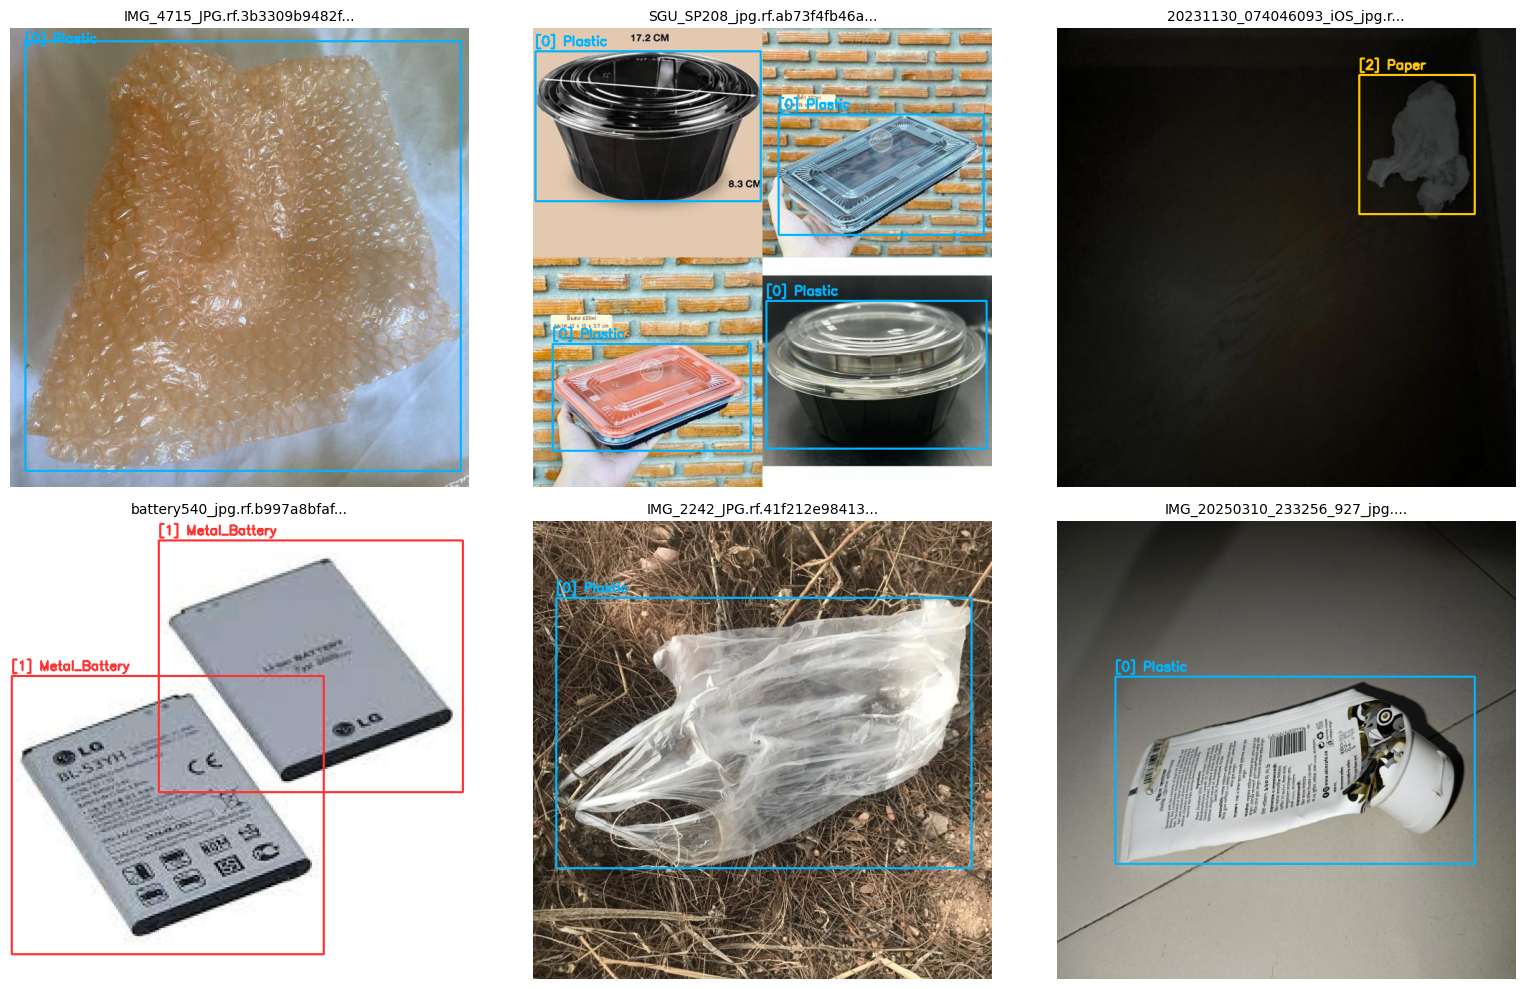

In [10]:
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import yaml
from pathlib import Path

PROCESSED_DIR = Path("/content/data/processed")
with open(PROCESSED_DIR / "data.yaml", "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

class_names = cfg["names"]
train_img_dir = PROCESSED_DIR / "train" / "images"
train_lbl_dir = PROCESSED_DIR / "train" / "labels"

# Lấy danh sách các file nhãn có chứa ít nhất 1 vật thể
non_empty_lbls = [p for p in train_lbl_dir.glob("*.txt") if p.stat().st_size > 0]
sample_lbls = random.sample(non_empty_lbls, min(6, len(non_empty_lbls)))

# Bảng màu RGB cho 6 lớp
COLORS = [
    (0, 180, 255),   # 0: Plastic (Xanh dương sáng)
    (255, 50, 50),   # 1: Metal_Battery (Đỏ cảnh báo)
    (255, 200, 0),   # 2: Paper (Vàng)
    (0, 220, 150),   # 3: Glass (Xanh ngọc)
    (50, 205, 50),   # 4: Organic (Xanh lá)
    (200, 0, 255)    # 5: Medical (Tím nguy hại)
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, lbl_path in enumerate(sample_lbls):
    # Tìm file ảnh tương ứng
    img_candidates = list(train_img_dir.glob(f"{lbl_path.stem}.*"))
    if not img_candidates:
        continue

    img_bgr = cv2.imread(str(img_candidates[0]))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w, _ = img_rgb.shape

    with open(lbl_path, "r", encoding="utf-8") as lf:
        for line in lf:
            parts = line.strip().split()
            cid = int(parts[0])
            coords = [float(x) for x in parts[1:]]

            # Hỗ trợ vẽ cả Bounding Box chuẩn (4 số) lẫn Polygon (nhiều điểm)
            if len(coords) == 4:
                xc, yc, bw, bh = coords
                x1 = int((xc - bw / 2) * w)
                y1 = int((yc - bh / 2) * h)
                x2 = int((xc + bw / 2) * w)
                y2 = int((yc + bh / 2) * h)
            else:
                xs = coords[0::2]
                ys = coords[1::2]
                x1, x2 = int(min(xs) * w), int(max(xs) * w)
                y1, y2 = int(min(ys) * h), int(max(ys) * h)

            color = COLORS[cid % len(COLORS)]
            cv2.rectangle(img_rgb, (x1, y1), (x2, y2), color, 2)
            label_text = f"[{cid}] {class_names[cid]}"
            cv2.putText(img_rgb, label_text, (x1, max(20, y1 - 8)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

    axes[idx].imshow(img_rgb)
    axes[idx].set_title(lbl_path.name[:28] + "...", fontsize=10)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [11]:
from google.colab import drive
import shutil
from pathlib import Path

# 1. Kết nối Google Drive
drive.mount('/content/drive')

# 2. Tạo thư mục lưu trữ dự án trên Google Drive
DRIVE_BACKUP_DIR = Path("/content/drive/MyDrive/HUST_IntroAI_WasteProject")
DRIVE_BACKUP_DIR.mkdir(parents=True, exist_ok=True)

# 3. Nén thư mục /content/data/processed thành file zip và copy lên Drive
print("Đang nén bộ dữ liệu 6 lớp đã chuẩn hóa...")
zip_path = shutil.make_archive("/content/waste_dataset_6classes_bfo", "zip", "/content/data/processed")
shutil.copy2(zip_path, DRIVE_BACKUP_DIR / "waste_dataset_6classes_bfo.zip")

# Sao lưu luôn file script remap_labels.py lên Drive
shutil.copy2("/content/scripts/remap_labels.py", DRIVE_BACKUP_DIR / "remap_labels.py")

print(f"[HOÀN TẤT] Đã sao lưu dataset 6 lớp tại: {DRIVE_BACKUP_DIR / 'waste_dataset_6classes_bfo.zip'}")

Mounted at /content/drive
Đang nén bộ dữ liệu 6 lớp đã chuẩn hóa...
[HOÀN TẤT] Đã sao lưu dataset 6 lớp tại: /content/drive/MyDrive/HUST_IntroAI_WasteProject/waste_dataset_6classes_bfo.zip


In [12]:
import torch
from pathlib import Path
from ultralytics import YOLO
from google.colab import drive

# 1. Đảm bảo Google Drive đã được kết nối để lưu checkpoint trực tiếp
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

# 2. Định nghĩa đường dẫn file data.yaml (6 lớp BFO) và thư mục lưu kết quả trên Drive
DATA_YAML_PATH = Path("/content/data/processed/data.yaml")
assert DATA_YAML_PATH.exists(), "LỖI: Không tìm thấy /content/data/processed/data.yaml! Hãy chạy lại Cell 4."

DRIVE_OUTPUT_DIR = Path("/content/drive/MyDrive/HUST_IntroAI_WasteProject/runs")
DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 3. Khởi tạo mô hình YOLOv12-Nano với trọng số Pre-trained trên tập COCO (2.55M params - Table 3)
model = YOLO("yolo12n.pt")

# 4. Bắt đầu huấn luyện theo đúng bộ Hyperparameters tại Table 2 & Section 3.2 (Dipo et al., 2025)
results = model.train(
    data=str(DATA_YAML_PATH),
    epochs=100,                  # Số vòng lặp huấn luyện (Table 2: 100 epochs)
    batch=16,                    # Kích thước lô (Table 2: Batch size = 16)
    imgsz=640,                   # Kích thước ma trận ảnh chuẩn hóa (Section 3.3: 640x640)
    optimizer="SGD",             # Bộ tối ưu hóa Stochastic Gradient Descent (Table 2)
    lr0=0.01,                    # Tốc độ học ban đầu (Table 2: Learning rate = 0.01)
    weight_decay=0.0005,         # Hệ số phạt L2 chống Overfitting (Table 2: 0.0005)
    patience=50,                 # Early stopping nếu 50 epochs liên tiếp không tăng mAP (Section 4.4)
    degrees=15.0,                # Xoay ảnh ngẫu nhiên trong khoảng [-15, +15] độ (Section 3.2)
    hsv_v=0.25,                  # Thay đổi độ sáng (Brightness) ngẫu nhiên +-25% (Section 3.2)
    fliplr=0.5,                  # Xác suất lật ngang ảnh 50% (Section 3.2)
    scale=0.5,                   # Co giãn kích thước vật thể (Scaling - Section 3.2)
    device=0,                    # Ép buộc chạy trên GPU NVIDIA Tesla T4 (CUDA:0)
    workers=2,                   # Số luồng CPU nạp dữ liệu song song trên Colab
    project=str(DRIVE_OUTPUT_DIR),
    name="yolov12n_bfo_6classes",
    exist_ok=True,
    pretrained=True,             # Sử dụng Transfer Learning từ COCO (Table 2)
    plots=True,                  # Tự động vẽ Confusion Matrix, PR Curve, Loss Curve
    save=True,
    save_period=10               # Cứ mỗi 10 epochs lưu thêm 1 bản backup trọng số
)

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/processed/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.25, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov12n_bfo_6classes, nbs=64, nms=None, opset=None, 

In [13]:
from ultralytics import YOLO
from pathlib import Path
import numpy as np

BEST_WEIGHTS_PATH = Path("/content/drive/MyDrive/HUST_IntroAI_WasteProject/runs/yolov12n_bfo_6classes/weights/best.pt")
assert BEST_WEIGHTS_PATH.exists(), f"Không tìm thấy trọng số tại {BEST_WEIGHTS_PATH}"

# 1. Nạp trọng số tốt nhất đã huấn luyện
best_model = YOLO(str(BEST_WEIGHTS_PATH))

# 2. Chạy đánh giá trên tập TEST độc lập (split='test')
print("Đang chấm điểm mô hình trên tập TEST (1.085 ảnh)...")
metrics = best_model.val(
    data="/content/data/processed/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

# 3. Tính toán F1-Score theo Công thức (1) trang 12 của Dipo et al. (2025)
mp = metrics.box.mp       # Mean Precision
mr = metrics.box.mr       # Mean Recall
map50 = metrics.box.map50 # mAP@0.5
map50_95 = metrics.box.map # mAP@0.5:0.95
f1_score = (2 * mp * mr) / (mp + mr + 1e-8)

print("\n=====================================================================")
print("KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (SO SÁNH VỚI BENCHMARK DIPO ET AL.)")
print("=====================================================================")
print(f"- Mean Precision (P)  : {mp:.4f}  (Bài báo gốc: 0.7300)")
print(f"- Mean Recall (R)     : {mr:.4f}  (Bài báo gốc: 0.7700)")
print(f"- F1-Score            : {f1_score:.4f}  (Mục tiêu PEAS >= 0.7500)")
print(f"- mAP@0.5             : {map50:.4f}  (Mục tiêu PEAS >= 0.7800)")
print(f"- mAP@0.5:0.95        : {map50_95:.4f}")
print("---------------------------------------------------------------------")
print("CHI TIẾT THEO TỪNG THỰC THỂ VẬT CHẤT (BFO MATERIAL ENTITY):")
print(f"{'ID':<4} | {'Tên Lớp':<15} | {'Precision':<10} | {'Recall':<10} | {'mAP@0.5':<10}")
print("-" * 58)
for idx, class_name in best_model.names.items():
    p_i, r_i, ap50_i, _ = metrics.box.class_result(idx)
    print(f"[{idx}]  | {class_name:<15} | {p_i:10.4f} | {r_i:10.4f} | {ap50_i:10.4f}")
print("=====================================================================")

Đang chấm điểm mô hình trên tập TEST (1.085 ảnh)...
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 160 layers, 2,572,842 parameters, 0 gradients, 7.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 839.0±516.2 MB/s, size: 56.2 KB)
val: Scanning /content/data/processed/test/labels... 1085 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1085/1085 505.0it/s 2.1s
val: New cache created: /content/data/processed/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 68/68 4.9it/s 13.9s
                   all       1085       3132      0.876      0.778      0.831       0.63
               Plastic        499       2235      0.939      0.947      0.968      0.896
         Metal_Battery        214        434      0.956      0.781      0.883      0.654
                 Paper        232        242      0.967      0.965      0.976      0.689
            

In [14]:
import shutil
from pathlib import Path
from google.colab import files

TRAIN_RUN_DIR = Path("/content/drive/MyDrive/HUST_IntroAI_WasteProject/runs/yolov12n_bfo_6classes")
EXPORT_DIR = Path("/content/export_for_local_pc")

if EXPORT_DIR.exists():
    shutil.rmtree(EXPORT_DIR)

(EXPORT_DIR / "metrics").mkdir(parents=True, exist_ok=True)

# 1. Copy trọng số best.pt ra thư mục xuất
best_pt_src = TRAIN_RUN_DIR / "weights" / "best.pt"
shutil.copy2(best_pt_src, EXPORT_DIR / "best.pt")

# 2. Copy toàn bộ biểu đồ đánh giá và file log CSV vào thư mục metrics/
metric_Artifacts = [
    "results.png",
    "results.csv",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "F1_curve.png",
    "PR_curve.png",
    "P_curve.png",
    "R_curve.png",
    "labels.jpg"
]

for item in metric_Artifacts:
    src_file = TRAIN_RUN_DIR / item
    if src_file.exists():
        shutil.copy2(src_file, EXPORT_DIR / "metrics" / item)

# 3. Nén thành 1 file zip duy nhất và tải trực tiếp về máy tính cá nhân
zip_export = shutil.make_archive("/content/models_artifact_bundle", "zip", EXPORT_DIR)
print(f"[OK] Đã đóng gói trọng số và biểu đồ tại: {zip_export} ({Path(zip_export).stat().st_size / (1024*1024):.2f} MB)")
files.download(zip_export)

[OK] Đã đóng gói trọng số và biểu đồ tại: /content/models_artifact_bundle.zip (5.39 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>